# Inlämningsuppgift - Hälsostudie

I denna rapport kommer vi gå igenom hälsostudien och analysera resultaten från denna. Detta kommer göras på ett datadrivet sätt för att kunna dra relevanta slutsatser. 

### Importer och datainläsning

Nedan importeras relevanta pythonpaket som används i rapporten och en första inläsning av data från hälsorapporten.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df=pd.read_csv("../data/health_study_dataset.csv")

Nedan gör vi ett par kontroller på datan för att se så inget ser konstigt ut vid första anblick.
Det vi kan se är att vi har 9 kolumner med 800 rader data. 
Vi kan även se att det inte finns NA celler eller dubbletter. 

In [3]:
display(df.describe())

print("Saknade värden:")
print(df.isna().sum())

print(f"\nAntal dubbletter: {df.duplicated().sum()}")



,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


Saknade värden:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Antal dubbletter: 0


In [4]:
for col in ["age","height","weight","systolic_bp","cholesterol"]:
    print(col, min(df[col]))

for col in ["age","height","weight","systolic_bp","cholesterol"]:
    print(col, max(df[col]))

age 18
height 144.4
weight 33.7
systolic_bp 106.8
cholesterol 2.5
age 90
height 200.4
weight 114.4
systolic_bp 185.9
cholesterol 7.88


### Beskrivande statistik 

Nedan kommer vi undersöka 5 olika variabler: Ålder, vikt, längd, blodtryck och kolesterolvärden. 
För samtliga kommer vi beräkna medelvärde, median, minimum och maximum.

In [5]:
cols = ["age","weight","height","systolic_bp","cholesterol"]
summary=df[cols].agg(
    ["mean","median","min","max"]
).T

summary

,mean,median,min,max
age,49.426250,50.00,18.0,90.00
weight,73.413000,73.20,33.7,114.40
height,171.849250,171.35,144.4,200.40
systolic_bp,149.178625,149.40,106.8,185.90
cholesterol,4.929150,4.97,2.5,7.88


I tabellen ovan kan vi se:

Medelåldern är ca 49 och medianåldern är 50, dock en stor skillnad på den yngsta och äldsta som är 18 respektive 90 år gamla. 

Viktens medelvärde och median ligger båda på ca 73 kg, men även här en stor skillnad på max och min (33.7 respektive 114.40 kilo).

Längden har samma mönster, ca 171 i medelvärde/median, minsta värdet 144.4 cm och längsta personen är 200.40 cm.

Även kolesterolet följer samma mönster, medel/median 4.93/4.97 , min/max 2.5/7.88.

Vad gäller blodtrycket så har vi en median på 149.40 , medans lägsta värdet är 106.8 och det högsta värdet är 185.90. 


Text(0.5, 1.0, 'Fördelning över systoliskt blodtryck')

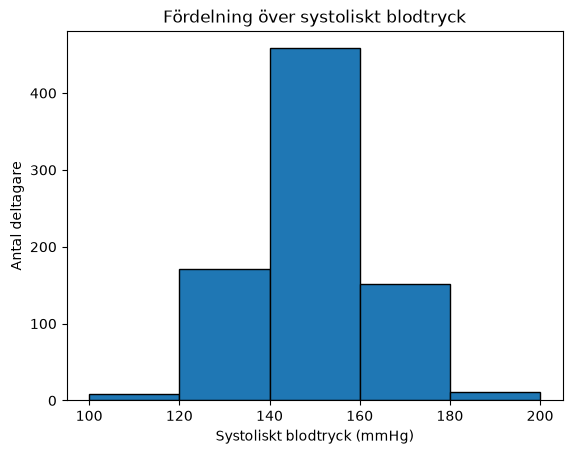

In [6]:
bins = [100, 120, 140, 160, 180, 200]
plt.hist(df["systolic_bp"],bins=bins,edgecolor="black")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal deltagare")
plt.title("Fördelning över systoliskt blodtryck")

I histogrammet ovan kan vi se deltagarnas systoliska blodtryck. Det visar att majoriteten av deltagarna har ett blodtryck mellan 140-160, och fördelningen är symmetrisk runt 150, få observationer i ytterkanterna. 

Vidare vill vi se hur detta förändras mellan de olika åldersgrupperna.

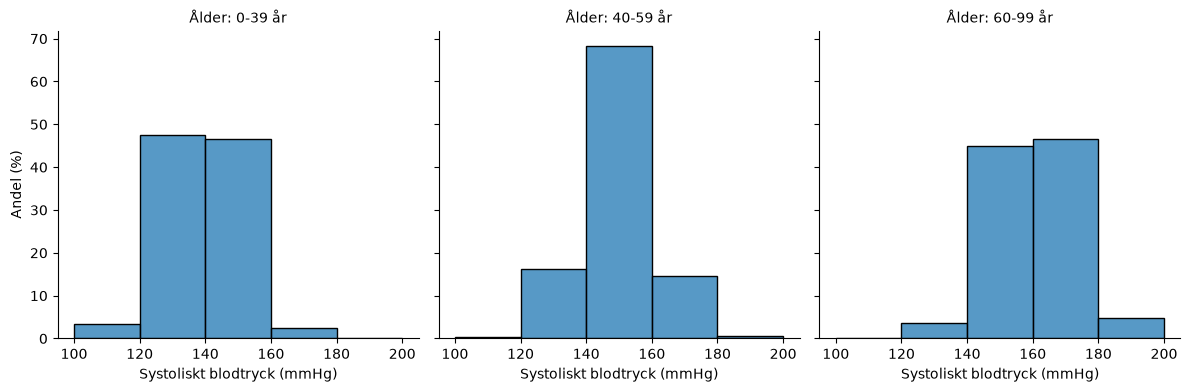

In [7]:
df["age_grp"]=pd.cut(
    df["age"],
    bins=[0,40,60,100],
    labels=["0-39","40-59","60-99"],
    right=False
)

g = sns.FacetGrid(
    df,
    col="age_grp",
    col_wrap=3,
    sharex=True,
    sharey=True,
    height=4
)

g.map_dataframe(
    sns.histplot,
    x="systolic_bp",
    bins=[100, 120, 140, 160, 180, 200],
    stat="percent",
    edgecolor="black"
)

g.set_axis_labels("Systoliskt blodtryck (mmHg)", "Andel (%)")
g.set_titles("Ålder: {col_name} år")


Här kan vi tydligt se att blodtrycksfördelningen förskjuts åt höger med stigande ålder, där va 25% av deltagarna ingår i 0-39 år, 50% i 40-59 år och 25% i den äldsta åldersgruppen. 

Nästa sak vi tittar på är skillnaden mellan män och kvinnor i viktaspekten. 

Text(0.5, 1.0, 'Viktfördelning uppdelat på kön')

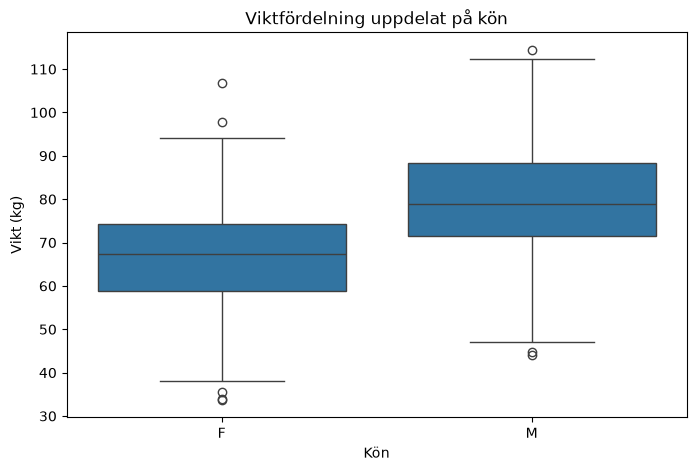

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="weight"
)

plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")
plt.title("Viktfördelning uppdelat på kön")

Boxploten visar en tydlig skillnad i viktfördelningen mellan kvinnor och män. Medianvikten är ungefär 67 kg för kvinnor och 79 kg för män. Spridningen inom de mittersta 50 procenten är däremot relativt likartad mellan grupperna.

Båda grupperna innehåller ett antal avvikande observationer, både över och under den huvudsakliga viktfördelningen. Dessa bör inte automatiskt betraktas som felaktiga värden.

Vi fortsätter med att undersöka hur rökning påverkar resultaten av studien.

In [9]:
smoker_pct = df["smoker"].value_counts(normalize=True) * 100

print(smoker_pct)

smoker
No     73.375
Yes    26.625
Name: proportion, dtype: float64


Vi ser ovan att ca 1/4 av deltagarna är rökare.
Nedan visualiserar vi även detta.

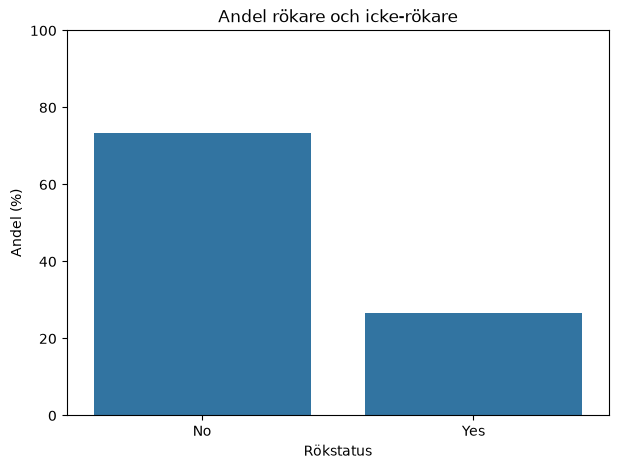

In [10]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=smoker_pct.index,
    y=smoker_pct.values
)

plt.xlabel("Rökstatus")
plt.ylabel("Andel (%)")
plt.title("Andel rökare och icke-rökare")
plt.ylim(0, 100)

plt.show()

Dock säger detta väldigt lite om hur mycket samband rökning faktiskt har till sjukdomen vi undersöker. 
Nedan visualiserar vi istället hur stor andel som är sjuka och grupperar detta i rökare och icke rökare. 

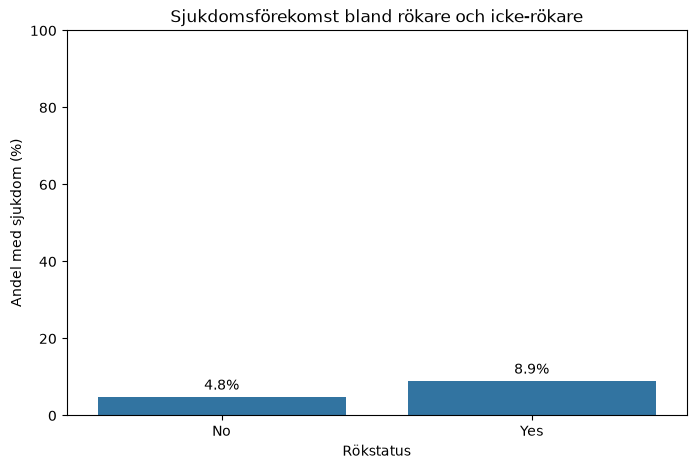

In [11]:
disease_by_smoking = (
    df.groupby("smoker")["disease"]
    .mean() * 100
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=disease_by_smoking.index,
    y=disease_by_smoking.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.xlabel("Rökstatus")
plt.ylabel("Andel med sjukdom (%)")
plt.title("Sjukdomsförekomst bland rökare och icke-rökare")
plt.ylim(0, 100)

plt.show()

Här kan vi se en tydlig skillnad mellan rökare och icke rökare. Även om andelen sjuka är relativt låg i båda kategorierna så skiljer det sig ca 4 procenenheter mellan varandra. Detta pekar på ett samband mellan rökning och sjukdomsförekomst, men inte nödvändigtvis att rökning är orsaken. 

### Sjukdomsfördelning och bernoulli simulering

Vi börjar med att beräkna sjukdomsandelen i datasetet för att sedan kunna simulera nya utfall.

In [12]:
p = df["disease"].mean()

print(f"Andel med sjukdom: {p:.2%}")
print(f"Antal deltagare: {len(df)}")
print(f"Antal med sjukdom: {df['disease'].sum()}")

Andel med sjukdom: 5.88%
Antal deltagare: 800
Antal med sjukdom: 47


In [13]:
rng = np.random.default_rng(42)

simulated = rng.binomial(
    n=1,
    p=p,
    size=1000
)

print(f"Simulerad sjukdomsandel: {simulated.mean():.2%}")

Simulerad sjukdomsandel: 5.40%


In [14]:
comparison = pd.DataFrame({
    "Grupp": ["Observerad", "Simulerad"],
    "Andel (%)": [
        p * 100,
        simulated.mean() * 100
    ]
})

print(comparison.round(2))

        Grupp  Andel (%)
0  Observerad       5.88
1   Simulerad       5.40


Av totalt 800 deltagare hade 47 sjukdomen, vilket motsvarar en observerad sjukdomsandel på 5,88 %.

För att undersöka slumpmässig variation genomfördes en Bernoulli-simulering med 1 000 oberoende utfall, där sannolikheten för sjukdom sattes till den observerade andelen.

Simuleringen resulterade i en sjukdomsandel på 5,40 %, vilket är 0,48 procentenheter lägre än den observerade andelen. Den skillnaden är tillräckligt liten för att den ska kunna förklaras av slumpmässig variation. 

Vi går vidare och skapar ett 95% konfidensintervall för systolisk blodtryck. 

In [15]:
bp = df["systolic_bp"].dropna()

mean_bp = bp.mean()
std_bp = bp.std(ddof=1)
n = len(bp)

print(f"Medelvärde: {mean_bp:.2f} mmHg")
print(f"Standardavvikelse: {std_bp:.2f} mmHg")
print(f"Antal observationer: {n}")

Medelvärde: 149.18 mmHg
Standardavvikelse: 12.79 mmHg
Antal observationer: 800


In [16]:
se = std_bp / np.sqrt(n)

print(f"Standardfel: {se:.3f} mmHg")

Standardfel: 0.452 mmHg


In [17]:
z = 1.96

ci_lower = mean_bp - z * se
ci_upper = mean_bp + z * se

print(f"95 % konfidensintervall: [{ci_lower:.2f}, {ci_upper:.2f}] mmHg")

95 % konfidensintervall: [148.29, 150.07] mmHg


Det genomsnittliga systoliska blodtrycket bland de 800 deltagarna var 149,18 mmHg, med en standardavvikelse på 12,79 mmHg.

Med hjälp av normalapproximationen beräknades ett 95-procentigt konfidensintervall till [148,29; 150,07] mmHg.

Intervallet är relativt smalt, vilket indikerar en hög precision i skattningen av populationsmedelvärdet. Detta beror delvis på det stora antalet observationer vilket ger ett lågt standardfel.

Trots att blodtrycket varierar mellan individerna kan medelvärdet därmed skattas relativt precist.

Det intressanta är om den matematiska modellen ovan skiljer sig från bootstrap metoden för att beräkna konfidensintervall. 

In [18]:
rng = np.random.default_rng(42)

bp = df["systolic_bp"].dropna()
n = len(bp)

bootstrap_means = []

for i in range(10000):
    sample = rng.choice(bp, size=n, replace=True)
    bootstrap_means.append(sample.mean())

In [19]:
ci_boot = np.percentile(bootstrap_means, [2.5, 97.5])

print(f"Bootstrap 95 % KI: [{ci_boot[0]:.2f}, {ci_boot[1]:.2f}]")

Bootstrap 95 % KI: [148.31, 150.05]


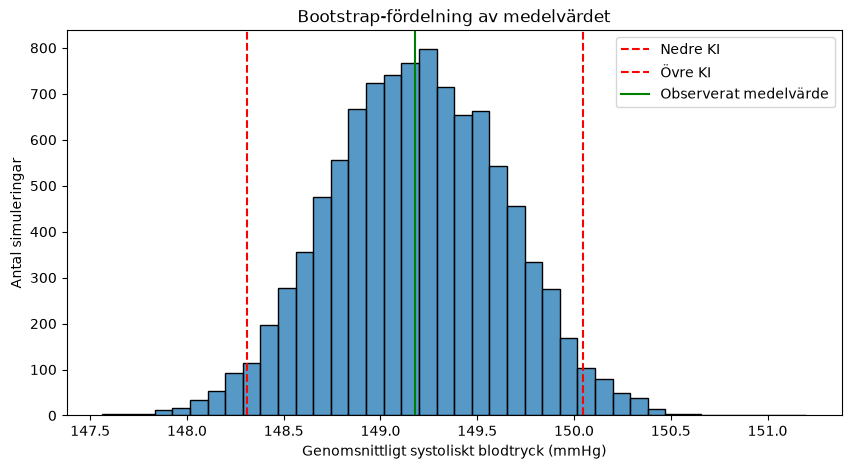

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(
    bootstrap_means,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    ci_boot[0],
    color="red",
    linestyle="--",
    label="Nedre KI"
)

plt.axvline(
    ci_boot[1],
    color="red",
    linestyle="--",
    label="Övre KI"
)

plt.axvline(
    bp.mean(),
    color="green",
    linestyle="-",
    label="Observerat medelvärde"
)

plt.xlabel("Genomsnittligt systoliskt blodtryck (mmHg)")
plt.ylabel("Antal simuleringar")
plt.title("Bootstrap-fördelning av medelvärdet")
plt.legend()

plt.show()

In [21]:
comparison = pd.DataFrame({
    "Metod": ["Normalapproximation", "Bootstrap"],
    "Nedre gräns": [ci_lower, ci_boot[0]],
    "Övre gräns": [ci_upper, ci_boot[1]]
})

print(comparison.round(2))

                 Metod  Nedre gräns  Övre gräns
0  Normalapproximation       148.29      150.07
1            Bootstrap       148.31      150.05


### Analys – Jämförelse mellan normalapproximation och bootstrap

För att undersöka osäkerheten i skattningen av det systoliska blodtrycket beräknas ett 95 procentigt konfidensintervall med 2 olika metoder. 
Normalapproximationen, dvs den matematiska modellen, gav ett intervall [148.29 , 150,07] medans bootstrap metoden med 10000 återdragningar ur datasettet gav [148.31 , 150.05]. 

Resultaten är nästan identiska och skiljer sig bara med ett par hundradelar. Normalapproximation kan därför anses vara väl fungerande för denna hälsostudie vilket sannolikt beror på det stora antalet i urvalet (800 st). 

Resultatet visar utöver detta att det genomsnittliga systoliska blodtrycket kan skattas med relativt hög precision. 

### Hypotesprövning - Rökare har högre systoliskt blodtryck än icke rökare.

Tidigare konstaterade vi att det finns ett samband mellan rökare och högre andel sjuka deltagare. 
Nedan kommer vi göra en hypotesprövning för att se om vi kan konstatera att rökare även har högre systoliskt blodtryck.

Detta kommer göras med ett ensidigt Welchs t-test och vill undersöka om medelvärdet för rökare är högre än vad det är för icke rökare. 

$$
H_0: \mu_{\text{rökare}} \leq \mu_{\text{icke-rökare}}
$$

$$
H_1: \mu_{\text{rökare}} > \mu_{\text{icke-rökare}}
$$

Vi använder signifikansnivå $\alpha=0.05$ dvs 5% risk att felaktigt förkasta nollhypotesen är acceptabelt.

In [22]:
df.groupby("smoker")["systolic_bp"].agg(
    ["count", "mean", "std", "median"]
).round(2)

,count,mean,std,median
smoker,,,,
No,587,149.05,12.63,149.3
Yes,213,149.52,13.27,149.5


Enligt tabellen ovan så ser vi att medelvärdet för rökare faktiskt är något högre än för icke-rökare om än väldigt lite högre. Även standardavvikelsen är något högre, dvs variationen mellan rökarna är högre.

In [23]:
from scipy import stats

smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

t_stat, p_value = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="greater"
)

print(f"t-statistik: {t_stat:.3f}")
print(f"p-värde: {p_value:.4f}")

t-statistik: 0.450
p-värde: 0.3264


### Resultat av hypotesprövning
Ovan utförde vi welchs t-test och får ett p-värde på 0.3264, vilket är ett högre värde än våran valda signifikansnivå (0.05). Vi har med andra ord ett resultat som inte är statistiskt signifikant och kan inte förkasta nollhypotesen. 

Tidigare såg vi som sagt en skillnad på sjukdomfall på rökare och icke-rökare, och även om det inte undersöktes på djupet så är det tydligt att olika variabler inte nödvändigtvis visar samma samband med rökning.

### Analys av hypotestest

Avslutningsvis undersöker vi power av vårt hypotestest, hur stor är sannolikheten att förkasta nollhypotesen när alternativhypotesen är sann?

Vi använder samma gruppstorlekar som i vårt tidigare test och antar att blodtrycket är normalfördelat inom grupperna. Sen simulerar vi flera nya dataset för att utföra analysen.

In [ ]:
rng = np.random.default_rng(42)

n_smokers = len(smokers)
n_non_smokers = len(non_smokers)

std_smokers = smokers.std()
std_non_smokers = non_smokers.std()

alpha = 0.05
n_simulations = 1000

effects = [0, 2, 5, 8, 10]
power_results = []

for effect in effects:
    significant = 0

    for _ in range(n_simulations):
        simulated_non = rng.normal(
            loc=149,
            scale=std_non_smokers,
            size=n_non_smokers
        )

        simulated_smokers = rng.normal(
            loc=149 + effect,
            scale=std_smokers,
            size=n_smokers
        )

        t_stat, p_value = stats.ttest_ind(
            simulated_smokers,
            simulated_non,
            equal_var=False,
            alternative="greater"
        )

        if p_value < alpha:
            significant += 1

    power = significant / n_simulations
    power_results.append(power)

    print(f"Skillnad: {effect:2d} mmHg | Power: {power:.1%}")

Skillnad:  0 mmHg | Power: 4.6%
Skillnad:  2 mmHg | Power: 60.5%
Skillnad:  5 mmHg | Power: 100.0%
Skillnad:  8 mmHg | Power: 100.0%
Skillnad: 10 mmHg | Power: 100.0%


### Power analys av hypotesprövning

Vi har en del olika nivåer i skillnader
När där inte finns någon skillnad blir testet signifikant i 4,6% av simuleringarna. 
När skillnaden är 2 mmHg hittar vi skillnaden i 60,5 % av simuleringarna, dvs vi hittar inte skillnaden nästan 40% av gångerna.
Vid högre skillnader blir samtliga simuleringar signifikanta.

Jämför vi med vår tidigare test där vi hade en observerad skillnad på 0,47 mmHg så går resultatet i linje med ovan, det betyder inte att det inte finns någon skillnad men vi lyckas med våran metod ej upptäcka den med ett signifikant resultat. Vi kan dra slutsatsen att testet har en begränsad förmåga att urskilja mindre skillnader.

### Sammanfattning och slutsats

I denna rapport har vi analyserat data från en hälsostudie med 800 deltagare. Vi har undersökt bland annat ålder, vikt, längd, blodtryck, kolesterol och rökning med hjälp av beskrivande statistik, visualiseringar och olika statistiska metoder.

I den beskrivande analysen kunde vi bland annat se att det systoliska blodtrycket tenderar att öka med åldern. Vi såg även en skillnad i vikt mellan män och kvinnor samt att andelen deltagare med sjukdom var högre bland rökare än bland icke-rökare. Det är dock viktigt att komma ihåg att ett observerat samband inte nödvändigtvis innebär att det finns ett orsakssamband.

Vi undersökte även osäkerheten kring det genomsnittliga systoliska blodtrycket genom att beräkna ett 95-procentigt konfidensintervall med både normalapproximation och bootstrap. Båda metoderna gav nästan identiska resultat, vilket tyder på att normalapproximationen fungerar bra för skattningen av medelvärdet i detta dataset.

Vid hypotesprövningen undersökte vi om rökare hade ett högre genomsnittligt systoliskt blodtryck än icke-rökare. Skillnaden var endast 0,47 mmHg och testet gav ett p-värde på 0,3264. Vi kunde därför inte förkasta nollhypotesen vid vår valda signifikansnivå på 5 %.

Avslutningsvis genomförde vi en power-analys som visade att vårt test har god förmåga att upptäcka större skillnader i blodtryck, men sämre förmåga att upptäcka mindre skillnader. Att vi inte fick ett statistiskt signifikant resultat innebär därför inte att vi helt kan utesluta en mindre verklig skillnad.